# Vehicle Damage Claim Triage

A model reads one photo of a damaged car and says if the damage is **minor**, **moderate** or **severe**, so the claim can be sent to the right team. The code lives in `src/`. This notebook calls it and shows the results.

In [1]:
import sys
sys.path.append("..")  # to import the src folder

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report

from src.preprocessing import (CLASS_NAMES, IMAGE_SIZE, MODEL_PATH, TEST_DIR, TRAIN_DIR,
                               list_image_files, load_image,
                               load_test_data, load_train_and_validation)
from src.insights import image_features
from src.model import build_model, evaluate_model, load_saved_model, save_model, train_model
from src.prediction import predict_image

## 1. Data acquisition

Data: **Car Damage Severity Dataset** (Kaggle). `src/acquire_data.py` downloads it into `data/train` and `data/test`, with one folder per class.

In [2]:
if not (TRAIN_DIR / "minor").exists():
    from src.acquire_data import main as download_data
    download_data()

for folder in [TRAIN_DIR, TEST_DIR]:
    for name in CLASS_NAMES:
        print(folder.name, name, len(list_image_files(folder / name)), "images")

train minor 445 images
train moderate 460 images
train severe 467 images
test minor 82 images
test moderate 75 images
test severe 91 images


## Data cleaning

In [3]:
import hashlib
from PIL import Image

all_files = [p for split in (TRAIN_DIR, TEST_DIR) for name in CLASS_NAMES for p in list_image_files(split / name)]

unreadable, tiny, modes, groups = [], [], {}, {}
for path in all_files:
    try:
        with Image.open(path) as image:
            image.verify()
        with Image.open(path) as image:
            modes[image.mode] = modes.get(image.mode, 0) + 1
            if min(image.size) < 100:
                tiny.append(path)
    except OSError:
        unreadable.append(path)
        continue
    groups.setdefault(hashlib.md5(path.read_bytes()).hexdigest(), []).append(path)

duplicates = [paths for paths in groups.values() if len(paths) > 1]
print("Photos checked:", len(all_files))
print("Unreadable photos:", len(unreadable))
print("Colour modes:", modes)
print("Photos smaller than 100 pixels on one side:", len(tiny))
print("Groups of identical photos:", len(duplicates))

Photos checked: 1620
Unreadable photos: 0
Colour modes: {'RGB': 1620}
Photos smaller than 100 pixels on one side: 30
Groups of identical photos: 0


In [4]:
removed = 0
for paths in duplicates:
    in_test = [p for p in paths if TEST_DIR in p.parents]
    keep = in_test[0] if in_test else paths[0]
    for path in paths:
        if path != keep:
            path.unlink()
            removed += 1
print("Duplicate photos removed:", removed)

Duplicate photos removed: 0


## 2. Data exploration and visualizations

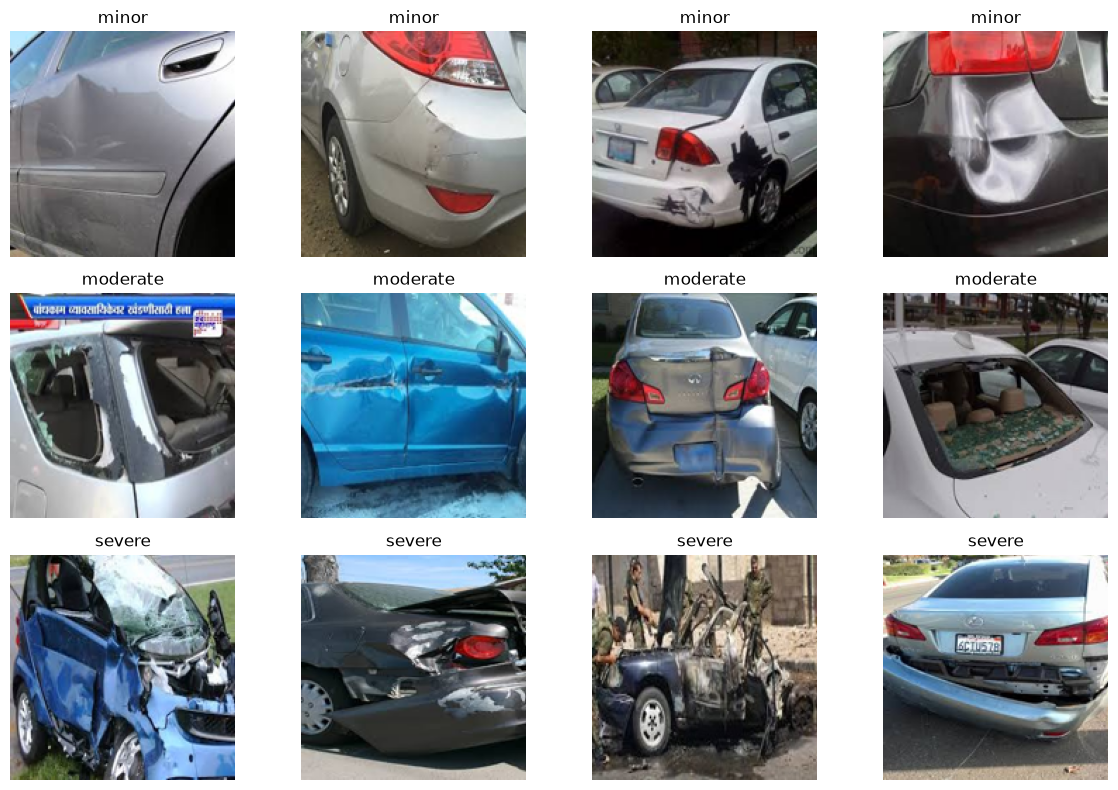

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(12, 8))
for row, name in enumerate(CLASS_NAMES):
    files = list_image_files(TRAIN_DIR / name)[:4]
    for col, file in enumerate(files):
        axes[row, col].imshow(load_image(file).astype("uint8"))
        axes[row, col].set_title(name)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

### Feature 1: photos per class

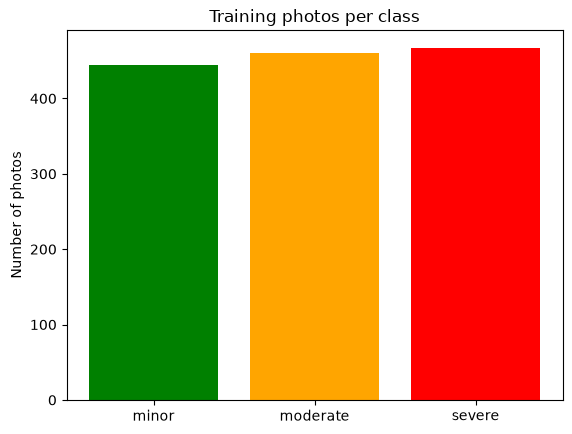

{'minor': 445, 'moderate': 460, 'severe': 467}


In [6]:
counts = {name: len(list_image_files(TRAIN_DIR / name)) for name in CLASS_NAMES}
plt.bar(counts.keys(), counts.values(), color=["green", "orange", "red"])
plt.title("Training photos per class")
plt.ylabel("Number of photos")
plt.show()
print(counts)

### Features 2 to 4: brightness, contrast and edge strength

- **Brightness** - how light the photo is.
- **Contrast** - how different the light and dark parts are.
- **Edge strength** - how many sharp lines the photo has.

In [7]:
rows = []
for name in CLASS_NAMES:
    for file in list_image_files(TRAIN_DIR / name):
        features = image_features(load_image(file))
        features["class"] = name
        rows.append(features)

features_table = pd.DataFrame(rows)
features_table.groupby("class").mean().round(2)

,brightness,contrast,edges
class,,,
minor,117.90,60.52,11.03
moderate,114.36,63.34,13.73
severe,111.85,64.11,15.39


### What story does the data tell?

- **Balance:** the three classes have almost the same number of photos, so accuracy is a fair metric.
- **Brightness and contrast:** almost the same for all classes (changes of about 5%). They do not help much.
- **Edges:** the clearest sign. Severe photos have about 40% more sharp lines than minor photos (15.4 and 11.0), from crumpled metal and broken glass.
- **Moderate** sits in the middle on every feature, so it is the easiest class to mix up.

## 3. Data preprocessing

1. Read each photo as RGB and resize it to 160 x 160.
2. Label it from the folder name (minor = 0, moderate = 1, severe = 2).
3. Split `train` into 80% training and 20% validation. `test` stays separate.
4. Group the photos in batches of 32.
5. Scale the pixels from 0-255 to -1 to 1 (inside the model).
6. Augment the training photos with random flips and small rotations.

In [8]:
train_data, validation_data = load_train_and_validation()
test_data = load_test_data()

images, labels = next(iter(train_data))
print("One batch of images:", images.shape)
print("One batch of labels:", labels.shape)
print("Pixel range before scaling:", float(images.numpy().min()), "to", float(images.numpy().max()))

Found 1372 files belonging to 3 classes.
Using 1098 files for training.
Found 1372 files belonging to 3 classes.
Using 274 files for validation.
Found 248 files belonging to 3 classes.
One batch of images: (32, 160, 160, 3)
One batch of labels: (32,)
Pixel range before scaling: 0.0 to 255.0


## 4. Model creation

Transfer learning: MobileNetV2 (ImageNet weights, frozen) with a new 3-class output layer.

| Technique | Used |
|---|---|
| Pretrained model | MobileNetV2 |
| Regularization | Dropout 0.3 and L2 |
| Data augmentation | Random flip and rotation |
| Optimizer | Adam |
| Early stopping | Patience 3 on validation loss |
| Learning rate schedule | Halved when progress stalls |

In [9]:
model = build_model()
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5. Model training

In [10]:
history = train_model(model, train_data, validation_data, epochs=15)

Epoch 1/15


c:\Users\user1\.vscode\ML_Pipeline_Summative\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


35/35 ━━━━━━━━━━━━━━━━━━━━ 26s 555ms/step - accuracy: 0.4581 - loss: 1.2223 - val_accuracy: 0.5401 - val_loss: 0.9555 - learning_rate: 0.0010
Epoch 2/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 17s 493ms/step - accuracy: 0.5583 - loss: 0.9680 - val_accuracy: 0.5511 - val_loss: 0.9173 - learning_rate: 0.0010
Epoch 3/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 17s 491ms/step - accuracy: 0.5984 - loss: 0.9084 - val_accuracy: 0.5949 - val_loss: 0.9027 - learning_rate: 0.0010
Epoch 4/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 17s 490ms/step - accuracy: 0.6321 - loss: 0.8280 - val_accuracy: 0.6204 - val_loss: 0.8733 - learning_rate: 0.0010
Epoch 5/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 17s 484ms/step - accuracy: 0.6330 - loss: 0.7826 - val_accuracy: 0.6350 - val_loss: 0.8715 - learning_rate: 0.0010
Epoch 6/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 19s 530ms/step - accuracy: 0.6658 - loss: 0.7508 - val_accuracy: 0.6095 - val_loss: 0.8593 - learning_rate: 0.0010
Epoch 7/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 22s 559ms/step - accuracy: 0.6721 - loss: 0.7457 - val_

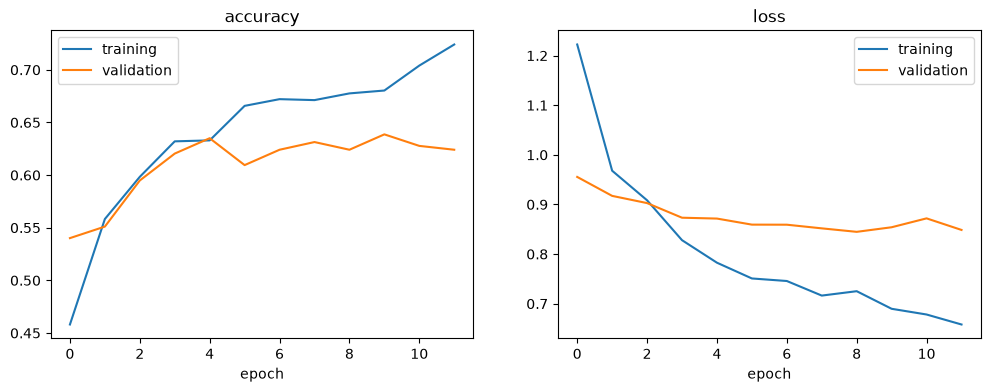

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, metric in zip(axes, ["accuracy", "loss"]):
    axis.plot(history.history[metric], label="training")
    axis.plot(history.history["val_" + metric], label="validation")
    axis.set_title(metric)
    axis.set_xlabel("epoch")
    axis.legend()
plt.show()

## 6. Model testing

The model is tested on `data/test` with loss, accuracy, precision, recall, F1 score and a confusion matrix.

In [12]:
results = evaluate_model(model, test_data)
for metric in ["loss", "accuracy", "precision", "recall", "f1_score"]:
    print(f"{metric:10s}: {results[metric]:.4f}")

loss      : 0.6782
accuracy  : 0.6694
precision : 0.6799
recall    : 0.6694
f1_score  : 0.6735


In [13]:
true_labels = np.concatenate([labels.numpy() for _, labels in test_data])
predicted_labels = model.predict(test_data, verbose=0).argmax(axis=1)
print(classification_report(true_labels, predicted_labels, target_names=CLASS_NAMES, zero_division=0))

              precision    recall  f1-score   support

       minor       0.74      0.73      0.74        82
    moderate       0.49      0.55      0.52        75
      severe       0.78      0.71      0.75        91

    accuracy                           0.67       248
   macro avg       0.67      0.66      0.67       248
weighted avg       0.68      0.67      0.67       248



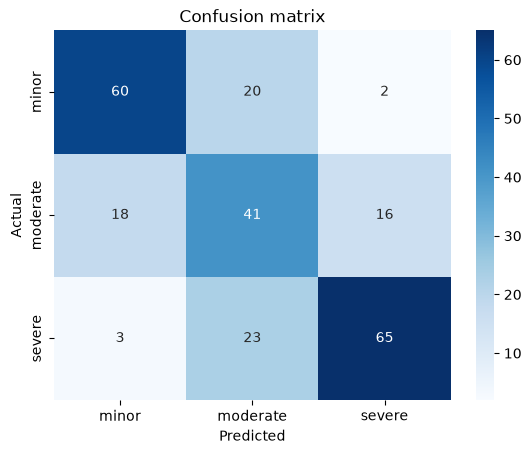

In [14]:
sns.heatmap(results["confusion_matrix"], annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix")
plt.show()

**Results:** 66.9% accuracy on the 248 test photos. Random guessing would reach about 33%.

- Best classes: severe (F1 0.75) and minor (F1 0.74).
- Hardest class: moderate (F1 0.52). It is often mixed with the other two.
- Minor and severe are rarely mixed (only 5 photos). These are the costly mistakes.

## 7. Save the model

In [15]:
save_model(model)
print("Model saved to", MODEL_PATH)

Model saved to C:\Users\user1\.vscode\ML_Pipeline_Summative\models\damage_model.h5


## 8. Prediction

`predict_image` in `src/prediction.py` returns the damage level, the confidence and the next step for the claim.

minor -> {'label': 'severe', 'confidence': 0.39695024490356445, 'probabilities': {'minor': 0.36952629685401917, 'moderate': 0.23352348804473877, 'severe': 0.39695024490356445}, 'claim_route': 'Escalate to a senior adjuster - possible total loss.'}
moderate -> {'label': 'severe', 'confidence': 0.43313366174697876, 'probabilities': {'minor': 0.22905543446540833, 'moderate': 0.3378108739852905, 'severe': 0.43313366174697876}, 'claim_route': 'Escalate to a senior adjuster - possible total loss.'}
severe -> {'label': 'severe', 'confidence': 0.9625334739685059, 'probabilities': {'minor': 0.0010792313842102885, 'moderate': 0.03638732060790062, 'severe': 0.9625334739685059}, 'claim_route': 'Escalate to a senior adjuster - possible total loss.'}


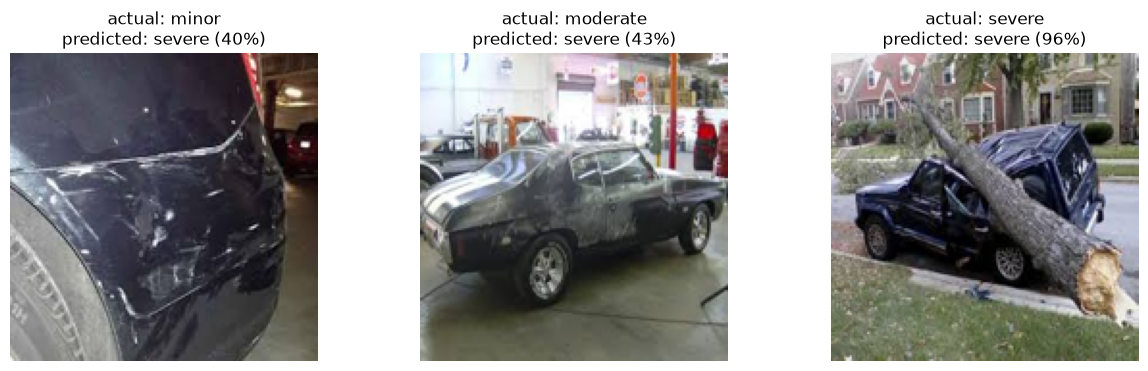

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, name in zip(axes, CLASS_NAMES):
    file = list_image_files(TEST_DIR / name)[0]
    result = predict_image(file)
    axis.imshow(load_image(file).astype("uint8"))
    axis.set_title(f"actual: {name}\npredicted: {result['label']} ({result['confidence']:.0%})")
    axis.axis("off")
    print(name, "->", result)
plt.show()